# Regresión Ridge: verificaciones y propiedades del estimador

Uso la notación de las notas: $\bar x_j=n^{-1}\sum_i x_{ij}$, $s_j^2=n^{-1}\sum_i(x_{ij}-\bar x_j)^2$ (varianza con
divisor $n$), $z_{ij}=(x_{ij}-\bar x_j)/s_j$ (ecuación 3.4), $Z\in\mathbb R^{n\times p}$ la matriz de los $z_{ij}$ y
$\mathbf 1\in\mathbb R^n$ el vector de unos. Supongo que ninguna predictora es constante, es decir, $s_j>0$.

## Verificación de $Z^T\mathbf 1=\mathbf 1^TZ=\mathbf 0$

````{prf:proposition}
:label: prop-z1
Las columnas de $Z$ suman cero: $Z^T\mathbf 1=\mathbf 0_p$ y $\mathbf 1^TZ=\mathbf 0_p^T$.
````

```{prf:proof}
La componente $j$ de $Z^T\mathbf 1$ es la suma de la columna $j$ de $Z$:

$$
\begin{aligned}
(Z^T\mathbf 1)_j&=\sum_{i=1}^n z_{ij}=\frac1{s_j}\sum_{i=1}^n(x_{ij}-\bar x_j)\\
&=\frac1{s_j}\Big(\sum_{i=1}^n x_{ij}-n\bar x_j\Big)=\frac1{s_j}\big(n\bar x_j-n\bar x_j\big)=0,
\end{aligned}
$$

donde usé que $\sum_i x_{ij}=n\bar x_j$ por la definición de media. Como esto vale para $j=1,\dots,p$, $Z^T\mathbf 1$ es el
vector cero de $\mathbb R^p$. Además $\mathbf 1^TZ=(Z^T\mathbf 1)^T$, porque $(AB)^T=B^TA^T$ y $(Z^T)^T=Z$; por lo tanto
$\mathbf 1^TZ$ es el vector fila cero.
```

Los dos productos tienen dimensiones distintas ($p\times1$ y $1\times p$); el "$0$" de las notas representa el vector cero
en cada caso.

**Consecuencia: la ecuación (3.8).** Al desarrollar la función objetivo (3.7) aparece el término cruzado
$2\beta_0^\star\,\mathbf 1^TZ\boldsymbol\beta_s$ (en las notas está escrito con $\beta_0$; debe ser $\beta_0^\star$). Por la
{prf:ref}`prop-z1` ese término vale cero, así que

$$
S_\lambda(\beta_0^\star,\boldsymbol\beta_s)=\boldsymbol y^T\boldsymbol y-2\beta_0^\star\,\boldsymbol y^T\mathbf 1-2\boldsymbol y^TZ\boldsymbol\beta_s
+n\beta_0^{\star2}+\boldsymbol\beta_s^TZ^TZ\boldsymbol\beta_s+\lambda\boldsymbol\beta_s^T\boldsymbol\beta_s ,
$$

con $\mathbf 1^T\mathbf 1=n$. Derivando respecto de $\beta_0^\star$ y usando $\boldsymbol y^T\mathbf 1=\sum_i y_i=n\bar y$:

$$
\frac{\partial S_\lambda}{\partial\beta_0^\star}=-2n\bar y+2n\beta_0^\star=0\ \Longrightarrow\ \hat\beta_0^\star=\bar y .
$$

Gracias a $\mathbf 1^TZ=\mathbf 0$, la ecuación de $\beta_0^\star$ no contiene a $\boldsymbol\beta_s$ y la de
$\boldsymbol\beta_s$ no contiene a $\beta_0^\star$: el intercepto y las pendientes se estiman por separado. Esa es la razón
de estandarizar.

## Verificación de las igualdades (3.11)

Las notas centran la respuesta, $\tilde y_i=y_i-\bar y$, y estandarizan las predictoras, $z_{ij}=(x_{ij}-\bar x_j)/s_j$; en
(3.11) se vuelve a escribir $y_i$ y $x_{ij}$ para los datos ya transformados.

````{prf:proposition}
:label: prop-311
$$\sum_{i=1}^n\tilde y_i=0,\qquad\sum_{i=1}^n z_{ij}=0,\qquad\sum_{i=1}^n z_{ij}^2=n,\qquad j=1,\dots,p.$$
````

```{prf:proof}
*Primera.* $\sum_i\tilde y_i=\sum_i y_i-n\bar y=n\bar y-n\bar y=0$.

*Segunda.* Es la componente $j$ de la {prf:ref}`prop-z1`.

*Tercera.* Sacando el factor común $1/s_j^2$ y usando la definición de $s_j^2$ con divisor $n$:

$$
\sum_{i=1}^n z_{ij}^2=\frac1{s_j^2}\sum_{i=1}^n(x_{ij}-\bar x_j)^2=\frac1{s_j^2}\cdot n\,s_j^2=n .
$$
```

Dos consecuencias:

1. **El intercepto se anula.** Con la respuesta centrada, $\hat\beta_0^\star=\bar{\tilde y}=\frac1n\sum_i\tilde y_i=0$, que es
   lo que permite trabajar con el modelo sin intercepto $\boldsymbol y=X\boldsymbol\beta+\boldsymbol\varepsilon$.
2. **$Z^TZ/n$ es la matriz de correlaciones.** La entrada $(j,k)$ de $Z^TZ/n$ es
   $\frac1n\sum_i z_{ij}z_{ik}=\frac{\frac1n\sum_i(x_{ij}-\bar x_j)(x_{ik}-\bar x_k)}{s_js_k}=r_{jk}$, y su diagonal vale $1$ por la
   tercera igualdad.

```{warning} Divisor de la varianza
La tercera igualdad depende de usar $s_j^2$ con divisor $n$, como en la ecuación 3.4. Con la varianza muestral de
divisor $n-1$ se obtendría $\sum_i z_{ij}^2=n-1$. `StandardScaler` de scikit-learn usa divisor $n$; `pandas.Series.std`
usa $n-1$ por defecto.
```

Lo compruebo con datos simulados:

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
n, p = 200, 4
X = rng.normal(size=(n, p)) * [1, 5, 30, 0.2] + [3, -2, 50, 0]   # escalas y medias distintas
y = 2 + X @ np.array([1.0, -0.5, 0.02, 4.0]) + rng.normal(size=n)

Z = (X - X.mean(0)) / X.std(0)          # np.std usa divisor n (ddof=0)
y_c = y - y.mean()
uno = np.ones(n)
pd.DataFrame({
    "suma de y centrada": [y_c.sum()],
    "max |Z^T 1|": [np.abs(Z.T @ uno).max()],
    "max |1^T Z|": [np.abs(uno @ Z).max()],
    "sumas de z^2 (divisor n)": [np.round((Z ** 2).sum(0), 10).tolist()],
    "sumas de z^2 (divisor n-1)": [np.round((((X - X.mean(0)) / X.std(0, ddof=1)) ** 2).sum(0), 10).tolist()],
}).T.rename(columns={0: "valor"})

,valor
suma de y centrada,0.0
max |Z^T 1|,0.0
max |1^T Z|,0.0
sumas de z^2 (divisor n),"[200.0, 200.0, 200.0, 200.0]"
sumas de z^2 (divisor n-1),"[199.0, 199.0, 199.0, 199.0]"


Las sumas son cero salvo error de redondeo (del orden de $10^{-13}$) y $\sum_i z_{ij}^2=n=200$ con divisor $n$, pero
$199$ con divisor $n-1$.

## Propiedades del estimador ridge (3.12)

**Supuestos** (los de las notas): $\boldsymbol y=X\boldsymbol\beta+\boldsymbol\varepsilon$ con $X\in\mathbb R^{n\times p}$ fija,
$\mathrm E(\boldsymbol\varepsilon)=\mathbf 0$ y $\mathrm{Cov}(\boldsymbol\varepsilon)=\sigma^2I_n$; $\lambda>0$. Defino

$$
W:=(X^TX+\lambda I_p)^{-1},\qquad \hat{\boldsymbol\beta}_R=WX^T\boldsymbol y .
$$

**$W$ existe y es simétrica.** $X^TX$ es simétrica y semidefinida positiva, porque
$\boldsymbol v^TX^TX\boldsymbol v=\|X\boldsymbol v\|^2\ge0$. Por el teorema espectral, $X^TX=Q\Lambda Q^T$ con $Q$ ortogonal y
$\Lambda=\mathrm{diag}(l_1,\dots,l_p)$, $l_j\ge0$. Entonces $X^TX+\lambda I_p=Q(\Lambda+\lambda I_p)Q^T$ tiene autovalores
$l_j+\lambda>0$, así que es invertible, con

$$
W=Q(\Lambda+\lambda I_p)^{-1}Q^T, \qquad W^T=W .
$$ (eq-w-espectral)

Esto vale aunque $X^TX$ sea singular (multicolinealidad perfecta o $p>n$): es la ventaja de ridge sobre mínimos
cuadrados. Usaré dos reglas de vectores aleatorios: $\mathrm E(A\boldsymbol u)=A\,\mathrm E(\boldsymbol u)$ y
$\mathrm{Cov}(A\boldsymbol u)=A\,\mathrm{Cov}(\boldsymbol u)A^T$ para una matriz fija $A$.

````{prf:proposition} Esperanza
:label: prop-esperanza
$\mathrm E(\hat{\boldsymbol\beta}_R)=(X^TX+\lambda I_p)^{-1}X^TX\boldsymbol\beta$.
````

```{prf:proof}
$\mathrm E(\boldsymbol y)=X\boldsymbol\beta+\mathrm E(\boldsymbol\varepsilon)=X\boldsymbol\beta$. Como $WX^T$ es fija,
$\mathrm E(\hat{\boldsymbol\beta}_R)=WX^T\,\mathrm E(\boldsymbol y)=WX^TX\boldsymbol\beta$.
```

````{prf:proposition} Covarianza
:label: prop-cov
$\mathrm{Cov}(\hat{\boldsymbol\beta}_R)=\sigma^2(X^TX+\lambda I_p)^{-1}X^TX(X^TX+\lambda I_p)^{-1}$.
````

```{prf:proof}
$\mathrm{Cov}(\boldsymbol y)=\mathrm{Cov}(\boldsymbol\varepsilon)=\sigma^2I_n$, porque $X\boldsymbol\beta$ es constante. Entonces

$$
\mathrm{Cov}(\hat{\boldsymbol\beta}_R)=(WX^T)\,\sigma^2I_n\,(WX^T)^T=\sigma^2\,WX^TXW^T=\sigma^2\,WX^TXW ,
$$

usando $(WX^T)^T=XW^T$ y $W^T=W$.
```

(En las notas la segunda línea dice $\mathrm{Cov}(\boldsymbol\beta_R)$; es la covarianza del estimador
$\hat{\boldsymbol\beta}_R$, porque $\boldsymbol\beta$ es un parámetro fijo.)

````{prf:proposition} Sesgo
:label: prop-sesgo
$\mathrm E(\hat{\boldsymbol\beta}_R-\boldsymbol\beta)=-\lambda(X^TX+\lambda I_p)^{-1}\boldsymbol\beta$.
````

```{prf:proof}
Sumo y resto $\lambda I_p$ dentro de $X^TX$:

$$
WX^TX=W\big[(X^TX+\lambda I_p)-\lambda I_p\big]=W W^{-1}-\lambda W=I_p-\lambda W .
$$

Con la {prf:ref}`prop-esperanza`, $\mathrm E(\hat{\boldsymbol\beta}_R)-\boldsymbol\beta=(I_p-\lambda W)\boldsymbol\beta-\boldsymbol\beta=-\lambda W\boldsymbol\beta$.
```

El sesgo es distinto de cero para $\lambda>0$ (salvo si $\boldsymbol\beta=\mathbf 0$): ridge cambia sesgo por varianza.

````{prf:proposition} Error cuadrático medio
:label: prop-ecm
Si $l_1,\dots,l_p$ son los autovalores de $X^TX$,

$$
\mathrm E\big[(\hat{\boldsymbol\beta}_R-\boldsymbol\beta)^T(\hat{\boldsymbol\beta}_R-\boldsymbol\beta)\big]
=\sigma^2\sum_{j=1}^p\frac{l_j}{(l_j+\lambda)^2}+\lambda^2\boldsymbol\beta^T(X^TX+\lambda I_p)^{-2}\boldsymbol\beta .
$$
````

```{prf:proof}
Sean $\boldsymbol m:=\mathrm E(\hat{\boldsymbol\beta}_R)$, $\boldsymbol u:=\hat{\boldsymbol\beta}_R-\boldsymbol m$ (aleatorio, con media cero) y
$\boldsymbol b:=\boldsymbol m-\boldsymbol\beta=-\lambda W\boldsymbol\beta$ (fijo). Entonces $\hat{\boldsymbol\beta}_R-\boldsymbol\beta=\boldsymbol u+\boldsymbol b$ y

$$
\mathrm E\big[(\boldsymbol u+\boldsymbol b)^T(\boldsymbol u+\boldsymbol b)\big]=\mathrm E(\boldsymbol u^T\boldsymbol u)+2\boldsymbol b^T\mathrm E(\boldsymbol u)+\boldsymbol b^T\boldsymbol b
=\mathrm E(\boldsymbol u^T\boldsymbol u)+\boldsymbol b^T\boldsymbol b ,
$$

porque $\mathrm E(\boldsymbol u)=\mathbf 0$.

*Término de varianza.* Un escalar es igual a su traza y $\mathrm{tr}(AB)=\mathrm{tr}(BA)$, así que
$\boldsymbol u^T\boldsymbol u=\mathrm{tr}(\boldsymbol u\boldsymbol u^T)$ y
$\mathrm E(\boldsymbol u^T\boldsymbol u)=\mathrm{tr}\,\mathrm E(\boldsymbol u\boldsymbol u^T)=\mathrm{tr}\,\mathrm{Cov}(\hat{\boldsymbol\beta}_R)$. Con la
{prf:ref}`prop-cov` y {eq}`eq-w-espectral`,

$$
\begin{aligned}
\mathrm{Cov}(\hat{\boldsymbol\beta}_R)&=\sigma^2\,Q(\Lambda+\lambda I)^{-1}Q^T\,Q\Lambda Q^T\,Q(\Lambda+\lambda I)^{-1}Q^T\\
&=\sigma^2\,Q\,\mathrm{diag}\!\Big(\frac{l_j}{(l_j+\lambda)^2}\Big)Q^T ,
\end{aligned}
$$

porque $Q^TQ=I$ y las matrices diagonales conmutan. Como $\mathrm{tr}(QDQ^T)=\mathrm{tr}(DQ^TQ)=\mathrm{tr}(D)$, la traza es
$\sigma^2\sum_j l_j/(l_j+\lambda)^2$.

*Término de sesgo.* $\boldsymbol b^T\boldsymbol b=\lambda^2\boldsymbol\beta^TW^TW\boldsymbol\beta=\lambda^2\boldsymbol\beta^TW^2\boldsymbol\beta
=\lambda^2\boldsymbol\beta^T(X^TX+\lambda I_p)^{-2}\boldsymbol\beta$.
```

El primer término es la suma de las varianzas de las componentes de $\hat{\boldsymbol\beta}_R$ (la traza de su matriz de
covarianzas) y el segundo es el cuadrado de la norma del sesgo, como dicen las notas.

**Lectura de la fórmula.** Con $\lambda=0$ se recupera mínimos cuadrados, sin sesgo y con varianza
$\sigma^2\sum_j 1/l_j$, que explota cuando algún $l_j$ es casi cero (multicolinealidad). Al aumentar $\lambda$, cada
término $l_j/(l_j+\lambda)^2$ baja y el sesgo sube. Si todos los $l_j>0$, la derivada del error cuadrático medio en
$\lambda=0$ es

$$
\frac{d}{d\lambda}\Big[\sigma^2\sum_j\frac{l_j}{(l_j+\lambda)^2}+\lambda^2\boldsymbol\beta^TW^2\boldsymbol\beta\Big]_{\lambda=0}=-2\sigma^2\sum_j\frac1{l_j^2}<0 ,
$$

porque la derivada del término de sesgo tiene el factor $\lambda$ y se anula en $0$. Por eso siempre existe un
$\lambda>0$ pequeño con menor error cuadrático medio que mínimos cuadrados (resultado de Hoerl y Kennard, 1970).

## Comprobación por simulación

Fijo una matriz $X$ con dos predictoras casi colineales, simulo $20\,000$ vectores de ruido y comparo los momentos
empíricos de $\hat{\boldsymbol\beta}_R$ con las fórmulas.

In [2]:
rng = np.random.default_rng(7)
n, p, sigma, lam = 60, 3, 1.5, 4.0
X = rng.normal(size=(n, p))
X[:, 2] = X[:, 1] + 0.05 * rng.normal(size=n)      # casi colineal con la columna 1
beta = np.array([1.0, 2.0, -1.0])
A = X.T @ X
W = np.linalg.inv(A + lam * np.eye(p))
l = np.linalg.eigvalsh(A)

R = 20_000
E = sigma * rng.normal(size=(R, n))
Y = X @ beta + E                                    # cada fila es una réplica de y
B = Y @ X @ W                                       # cada fila es un beta_R (W es simétrica)

teo = {
    "E(beta_R)": W @ A @ beta,
    "sesgo": -lam * W @ beta,
    "diag Cov(beta_R)": np.diag(sigma**2 * W @ A @ W),
}
emp = {
    "E(beta_R)": B.mean(0),
    "sesgo": B.mean(0) - beta,
    "diag Cov(beta_R)": B.var(0),
}
tabla = pd.DataFrame({k: [np.round(teo[k], 4), np.round(emp[k], 4)] for k in teo}, index=["fórmula", "simulación"]).T
ecm_teo = sigma**2 * np.sum(l / (l + lam) ** 2) + lam**2 * beta @ W @ W @ beta
ecm_emp = np.mean(np.sum((B - beta) ** 2, axis=1))
tabla.loc["ECM"] = [round(ecm_teo, 4), round(ecm_emp, 4)]
tabla

,fórmula,simulación
E(beta_R),"[0.896, 0.4953, 0.4676]","[0.8994, 0.4949, 0.4672]"
sesgo,"[-0.104, -1.5047, 1.4676]","[-0.1006, -1.5051, 1.4672]"
diag Cov(beta_R),"[0.0414, 0.0141, 0.0141]","[0.0416, 0.0141, 0.0143]"
ECM,4.4986,4.4983


Las fórmulas coinciden con la simulación hasta el error Monte Carlo. Para ver el intercambio entre sesgo y varianza,
comparo el error cuadrático medio teórico de ridge con el de mínimos cuadrados ($\lambda=0$):

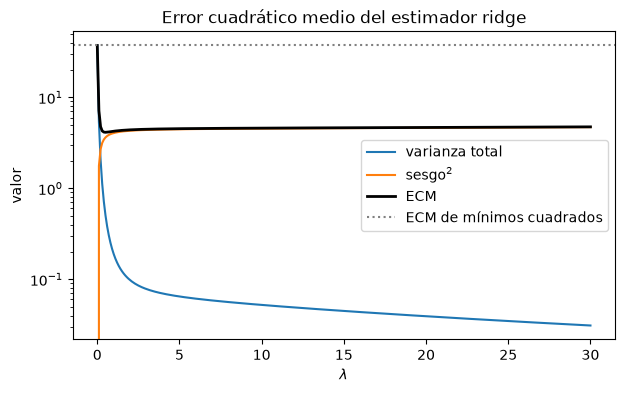

ECM con lambda=0: 37.124 | mínimo: 4.128 en lambda = 0.5


In [3]:
import matplotlib.pyplot as plt

lams = np.linspace(0, 30, 301)
var = [sigma**2 * np.sum(l / (l + t) ** 2) for t in lams]
ses = [t**2 * beta @ np.linalg.matrix_power(np.linalg.inv(A + t * np.eye(p)), 2) @ beta for t in lams]
ecm = np.add(var, ses)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lams, var, label="varianza total")
ax.plot(lams, ses, label="sesgo$^2$")
ax.plot(lams, ecm, "k", lw=2, label="ECM")
ax.axhline(ecm[0], color="gray", ls=":", label="ECM de mínimos cuadrados")
ax.set(xlabel=r"$\lambda$", ylabel="valor", yscale="log", title="Error cuadrático medio del estimador ridge")
ax.legend()
plt.show()
print(f"ECM con lambda=0: {ecm[0]:.3f} | mínimo: {ecm.min():.3f} en lambda = {lams[ecm.argmin()]:.1f}")